# TP3 - Regularización en MLP (20 Newsgroups)
### Redes Neuronales / Deep Learning

Continuación del TP2 (MLP). Se agregan como hiperparámetros las técnicas de regularización vistas en clase:

- **Regularización L1, L2 y L1+L2** sobre los pesos.
- **Dropout** en la entrada y en las capas ocultas (con *max-norm* opcional).
- **Batch Normalization**.

**Contenido**
1. Setup, datos y preprocesamiento (igual que el TP2).
2. MLP con dropout y BatchNorm, penalización L1/L2 y medición de pesos.
3. **Experimentos controlados:** la red que sobreajustaba en el TP2 (3 capas de 1024) contra cada técnica por separado, con varias semillas. Se miran curvas, ruido, valores absolutos de los pesos, tiempos y learning rate.
4. **Búsqueda con Optuna** que incluye las técnicas de regularización como hiperparámetros (mismo presupuesto que el TP2).
5. Entrenamiento final, evaluación en test, variabilidad entre semillas y comparación con el TP2.

Siguiendo las recomendaciones de clase y de la devolución del TP2: en los experimentos se cambia **una sola cosa por vez**, se repite con varias semillas, los tiempos se miden en el código y el test se usa solo al final.

> Recomendado: usar GPU en Colab (*Entorno de ejecución → Cambiar tipo de entorno de ejecución*).

## 0. Setup

In [1]:
!pip install -q mlflow optuna

In [2]:
import random
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

import mlflow
import optuna

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)
if device.type == "cpu":
    print("ATENCIÓN: sin GPU el entrenamiento va a ser bastante más lento.")

Usando dispositivo: cuda


In [3]:
for recurso in ["stopwords", "wordnet", "omw-1.4", "punkt", "punkt_tab"]:
    nltk.download(recurso, quiet=True)

## Configuración general

Los experimentos controlados son la parte más larga (15 configuraciones × 3 semillas). Para una corrida más rápida se puede usar `SEEDS_EXP = [0, 1]`.

In [4]:
# --- Búsqueda con Optuna (mismo presupuesto que el TP2) ---
N_TRIALS = 30
TIMEOUT_S = 20 * 60
EPOCHS_SEARCH = 8

# --- Experimentos controlados ---
EXP_HIDDEN = [1024, 1024, 1024]   # la red que sobreajustaba en el TP2
EXP_LR = 1e-3                     # Adam, como en el experimento de overfitting del TP2
EXP_BATCH = 64
EPOCHS_EXP = 15
SEEDS_EXP = [0, 1, 2]
# Preprocesamiento fijo para los experimentos: el mejor de la regresión softmax en el TP2
EXP_PREPROC = {"remove_sw": True, "norm": "stem", "ngram": (1, 1), "max_features": 10000, "min_df": 2}

# --- Entrenamiento final ---
SEEDS_FINAL = [0, 1, 2, 3, 4]
EVAL_BATCH = 1024

mlflow.end_run()
mlflow.set_experiment("mlp_regularizacion_20newsgroups")

2026/11/19 13:27:17 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/19 13:27:17 INFO mlflow.store.db.utils: Updating database tables
2026/11/19 13:27:23 INFO mlflow.tracking.fluent: Experiment with name 'mlp_regularizacion_20newsgroups' does not exist. Creating a new experiment.


<Experiment: artifact_location='/content/mlruns/1', creation_time=1795094843374, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1795094843374, lifecycle_stage='active', name='mlp_regularizacion_20newsgroups', tags={}, trace_location=None, workspace='default'>

## 1. Datos: 20 Newsgroups

In [5]:
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test = fetch_20newsgroups(subset="test", remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
y_train_full = np.array(newsgroups_train.target)
y_test = np.array(newsgroups_test.target)
print(f"Clases: {NUM_CLASSES} | Train: {len(y_train_full)} | Test: {len(y_test)}")

Clases: 20 | Train: 11314 | Test: 7532


## 2. Preprocesamiento y vectorización (del TP1)

In [6]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()


def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]
    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]
    return " ".join(tokens)


def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    vectorizer = TfidfVectorizer(ngram_range=ngram_range, max_features=max_features, min_df=min_df)
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer

In [7]:
# Precalculamos el preprocesamiento para las 6 combinaciones (es lo más lento del pipeline)
t0 = time.perf_counter()
preprocessed_cache = {}
for remove_sw in [False, True]:
    for norm in ["none", "stem", "lemmatize"]:
        train_proc = [preprocess_text(t, remove_sw, norm) for t in newsgroups_train.data]
        test_proc = [preprocess_text(t, remove_sw, norm) for t in newsgroups_test.data]
        preprocessed_cache[(remove_sw, norm)] = (train_proc, test_proc)
        print("  listo:", (remove_sw, norm))
print(f"Preprocesamiento total: {time.perf_counter() - t0:.1f} s")

  listo: (False, 'none')
  listo: (False, 'stem')
  listo: (False, 'lemmatize')
  listo: (True, 'none')
  listo: (True, 'stem')
  listo: (True, 'lemmatize')
Preprocesamiento total: 208.0 s


In [8]:
# Partición train/validación fija (misma que en los TPs anteriores)
idx_tr, idx_val = train_test_split(
    np.arange(len(y_train_full)), test_size=0.2, random_state=SEED, stratify=y_train_full
)
y_tr, y_val = y_train_full[idx_tr], y_train_full[idx_val]

vectorized_cache = {}


def get_search_features(remove_sw, norm, ngram, max_features, min_df):
    key = (remove_sw, norm, ngram, max_features, min_df)
    if key not in vectorized_cache:
        train_texts, _ = preprocessed_cache[(remove_sw, norm)]
        tr_texts = [train_texts[i] for i in idx_tr]
        val_texts = [train_texts[i] for i in idx_val]
        X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram, max_features, min_df)
        vectorized_cache[key] = (X_tr, X_val)
    return vectorized_cache[key]


def to_device(X, y):
    X_t = torch.tensor(X.toarray(), dtype=torch.float32, device=device)
    y_t = torch.tensor(y, dtype=torch.long, device=device)
    return X_t, y_t

## 3. Modelo: MLP con regularización

Recomendaciones de clase que se aplican en la implementación:

- **L1 / L2:** se suma a la loss `λ1·Σ|w|` y/o `λ2·Σw²` sobre los pesos de las capas lineales. **No se regularizan los bias** (ni los parámetros de BatchNorm). `λ` se busca en escala logarítmica. Con Adam, sumar L2 a la loss no es exactamente lo mismo que *weight decay* desacoplado (AdamW), porque Adam reescala el gradiente de cada peso.
- **Dropout:** `nn.Dropout` apaga activaciones al azar durante el entrenamiento y divide las que quedan por `keep_prob`, así lo que llega a la capa siguiente se mantiene en promedio. En evaluación no apaga nada. Se puede usar en la entrada y en las capas ocultas (valores entre 0.2 y 0.5).
- **Max-norm:** después de cada paso, si la norma de los pesos que entran a una neurona supera `c`, se reescalan para que valga `c` (en clase se sugiere `c` entre 4 y 5 junto con dropout).
- **BatchNorm:** orden `Linear (sin bias) → BatchNorm → activación`, porque el `beta` de BN cumple el rol del bias. En clase se recomienda no combinarlo con dropout. Ojo con la convención: en PyTorch `momentum=0.1` (default) equivale a `0.9` en Keras, porque PyTorch actualiza `running = (1 - momentum)·running + momentum·batch`.

In [9]:
ACTIVATIONS = {
    "relu": nn.ReLU,
    "tanh": nn.Tanh,
    "leaky_relu": nn.LeakyReLU,
    "gelu": nn.GELU,
}


class MLP(nn.Module):
    def __init__(self, input_dim, hidden_sizes, num_classes, activation="relu",
                 dropout_in=0.0, dropout_hidden=0.0, batchnorm=False):
        super().__init__()
        layers = []
        if dropout_in > 0:
            layers.append(nn.Dropout(dropout_in))            # dropout en la entrada (palabras)
        prev = input_dim
        for h in hidden_sizes:
            layers.append(nn.Linear(prev, h, bias=not batchnorm))  # con BN, beta reemplaza al bias
            if batchnorm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(ACTIVATIONS[activation]())
            if dropout_hidden > 0:
                layers.append(nn.Dropout(dropout_hidden))
            prev = h
        layers.append(nn.Linear(prev, num_classes))           # salida: logits
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def linear_weights(model):
    # Solo los pesos w de las capas lineales (sin bias ni parámetros de BatchNorm)
    return [m.weight for m in model.modules() if isinstance(m, nn.Linear)]


def penalty(model, l1, l2):
    total = 0.0
    for w in linear_weights(model):
        if l1 > 0:
            total = total + l1 * w.abs().sum()
        if l2 > 0:
            total = total + l2 * w.pow(2).sum()
    return total


@torch.no_grad()
def apply_max_norm(model, c):
    # Capas ocultas: limita la norma de los pesos que entran a cada neurona
    for w in linear_weights(model)[:-1]:
        norms = w.norm(dim=1, keepdim=True)
        w.mul_(torch.clamp(c / (norms + 1e-8), max=1.0))


HIST_EDGES = np.linspace(-8, 1, 91)   # bordes en log10(|w|)


@torch.no_grad()
def weight_stats(model):
    ws = [w.detach().abs().flatten() for w in linear_weights(model)]
    all_w = torch.cat(ws)
    log_first = torch.log10(ws[0].clamp(min=1e-8))
    ocultas = linear_weights(model)[:-1]
    return {
        # norma máxima de los pesos que entran a una neurona oculta (lo que limita max-norm)
        "max_norma_neurona": max((w.norm(dim=1).max().item() for w in ocultas), default=0.0),
        "mean_abs_w": all_w.mean().item(),
        "max_abs_w": all_w.max().item(),
        "frac_w_lt_1e-3": (all_w < 1e-3).float().mean().item(),
        "hist_capa1": torch.histc(log_first, bins=len(HIST_EDGES) - 1,
                                  min=HIST_EDGES[0], max=HIST_EDGES[-1]).cpu().numpy(),
    }


# Sanity check
_m = MLP(50, [32, 16], 20, "relu", dropout_in=0.2, dropout_hidden=0.5, batchnorm=True)
assert _m(torch.randn(4, 50)).shape == (4, 20)
print(_m)
print("Penalización L1+L2 inicial:", penalty(_m, 1e-4, 1e-4).item())

MLP(
  (net): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=50, out_features=32, bias=False)
    (2): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): Dropout(p=0.5, inplace=False)
    (5): Linear(in_features=32, out_features=16, bias=False)
    (6): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): ReLU()
    (8): Dropout(p=0.5, inplace=False)
    (9): Linear(in_features=16, out_features=20, bias=True)
  )
)
Penalización L1+L2 inicial: 0.02184031531214714


In [10]:
def make_optimizer(name, params, lr, opt_kwargs):
    if name == "adam":
        return optim.Adam(params, lr=lr, betas=(opt_kwargs["beta1"], opt_kwargs["beta2"]))
    if name == "rmsprop":
        return optim.RMSprop(params, lr=lr, alpha=opt_kwargs["alpha"], momentum=opt_kwargs["momentum"])
    if name == "sgd":
        return optim.SGD(params, lr=lr, momentum=opt_kwargs["momentum"])
    raise ValueError(name)


def opt_kwargs_from(params):
    if params["optimizer"] == "adam":
        return {"beta1": params["adam_beta1"], "beta2": params["adam_beta2"]}
    if params["optimizer"] == "rmsprop":
        return {"alpha": params["rmsprop_alpha"], "momentum": params["rmsprop_momentum"]}
    return {"momentum": params["sgd_momentum"]}


def config_from_params(p):
    """Traduce los hiperparámetros de Optuna a la configuración del modelo."""
    return {
        "hidden": [p[f"n_units_l{i}"] for i in range(p["n_layers"])],
        "activation": p["activation"],
        "dropout_in": p.get("dropout_in", 0.0),
        "dropout_hidden": p.get("dropout_hidden", 0.0),
        "batchnorm": p.get("batchnorm", False),
        "l1": p.get("l1", 0.0),
        "l2": p.get("l2", 0.0),
        "lr": p.get("lr", p.get("lr_sgd")),
        "ngram": (1, 1) if p["ngram_range"] == "1gram" else (1, 2),
    }

## 4. Entrenamiento

Igual que en el TP2, más:
- la penalización L1/L2 sumada a la loss (en `train_loss` se reporta solo la entropía cruzada, para compararla con la de validación),
- max-norm opcional después de cada paso,
- la loss de **cada lote**, para medir el ruido del entrenamiento.

`train_acc` se calcula durante el entrenamiento, con dropout activo y BatchNorm usando las estadísticas de cada lote. `val_acc` se calcula en modo evaluación.

In [11]:
criterion = nn.CrossEntropyLoss()


def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()


@torch.no_grad()
def evaluate(model, X, y):
    model.eval()
    total_loss, correct = 0.0, 0
    for i in range(0, len(y), EVAL_BATCH):
        logits = model(X[i:i + EVAL_BATCH])
        total_loss += criterion(logits, y[i:i + EVAL_BATCH]).item() * len(logits)
        correct += (logits.argmax(1) == y[i:i + EVAL_BATCH]).sum().item()
    return total_loss / len(y), correct / len(y)


def train_model(model, X_tr, y_tr, X_val, y_val, optimizer, epochs, batch_size,
                l1=0.0, l2=0.0, max_norm=None, trial=None, run_name="run", verbose=True):
    model.to(device)
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [],
            "epoch_time": [], "penalty": [], "batch_loss": []}
    n = len(y_tr)
    for epoch in range(epochs):
        sync()
        t0 = time.perf_counter()
        model.train()
        perm = torch.randperm(n, device=device)
        run_loss, run_pen, correct, seen = 0.0, 0.0, 0, 0
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            if len(idx) < 2:          # BatchNorm necesita al menos 2 ejemplos por lote
                continue
            xb, yb = X_tr[idx], y_tr[idx]
            optimizer.zero_grad()
            logits = model(xb)
            ce = criterion(logits, yb)
            pen = penalty(model, l1, l2)
            (ce + pen).backward()
            optimizer.step()
            if max_norm:
                apply_max_norm(model, max_norm)
            ce_val = ce.item()
            hist["batch_loss"].append(ce_val)
            run_loss += ce_val * len(idx)
            run_pen += (pen.item() if torch.is_tensor(pen) else pen) * len(idx)
            correct += (logits.argmax(1) == yb).sum().item()
            seen += len(idx)
        sync()
        epoch_time = time.perf_counter() - t0

        val_loss, val_acc = evaluate(model, X_val, y_val)
        hist["train_loss"].append(run_loss / seen)
        hist["train_acc"].append(correct / seen)
        hist["penalty"].append(run_pen / seen)
        hist["val_loss"].append(val_loss)
        hist["val_acc"].append(val_acc)
        hist["epoch_time"].append(epoch_time)

        if verbose:
            print(f"[{run_name}] ep {epoch + 1}/{epochs} - train_loss {hist['train_loss'][-1]:.4f} "
                  f"train_acc {hist['train_acc'][-1]:.4f} - val_loss {val_loss:.4f} "
                  f"val_acc {val_acc:.4f} - {epoch_time:.2f} s")
        if mlflow.active_run() is not None:
            mlflow.log_metrics({k: hist[k][-1] for k in hist if k != "batch_loss"}, step=epoch)

        if trial is not None:
            trial.report(val_acc, epoch)
            if trial.should_prune():
                trial.set_user_attr("history", {k: v for k, v in hist.items() if k != "batch_loss"})
                raise optuna.TrialPruned()
    return hist


def batch_noise(hist, last_epochs=3):
    """Ruido de lote a lote de la loss de train en las últimas épocas.
    Absoluto: desvío de la diferencia entre lotes consecutivos / raíz(2).
    Relativo: ruido absoluto dividido la loss media."""
    b = np.array(hist["batch_loss"])
    per_epoch = len(b) // len(hist["val_acc"])
    b = b[-last_epochs * per_epoch:]
    ruido = np.std(np.diff(b)) / np.sqrt(2)
    return ruido, ruido / max(b.mean(), 1e-8)

## 5. Experimentos controlados

Base: la red que sobreajustaba en el TP2 (3 capas de 1024, ReLU, Adam `lr=1e-3`, batch 64), con un preprocesamiento fijo. Cada configuración cambia **una sola cosa** respecto de la base y se entrena con 3 semillas.

| Grupo | Configuraciones | Qué se compara |
|---|---|---|
| Base | sin regularización, y con `lr` ×10 | referencia y efecto del `lr` solo |
| L2 | λ2 = 1e-5, 1e-4, 1e-3 | intensidad de L2 |
| L1 | λ1 = 1e-6, 1e-5, 1e-4 | intensidad de L1 |
| L1+L2 | λ1 = 1e-6 y λ2 = 1e-4 | combinación |
| Dropout | 0.2 / 0.5 en ocultas (0.2 en la entrada), 0.5 con `lr` ×10, y 0.5 con `lr` ×10 + max-norm 4 | recomendaciones de clase |

Para saber si max-norm llegó a actuar, se registra la mayor norma de los pesos que entran a una neurona oculta (`max_norma_neurona`). Si sin max-norm nunca supera 4, la restricción no cambia nada.
| BatchNorm | con `lr` base y con `lr` ×10 | si BN permite un `lr` más alto |

Los λ de L1 son más chicos que los de L2 porque `Σ|w|` es mucho mayor que `Σw²` cuando los pesos son menores que 1 (con 10000 entradas, la primera capa tiene más de 10 millones de pesos).

Todo se evalúa en **validación**. El test no se usa en esta sección.

In [12]:
EXPERIMENTS = {
    "base":                        {},
    "base lr×10":                  {"lr": EXP_LR * 10},
    "L2 1e-5":                     {"l2": 1e-5},
    "L2 1e-4":                     {"l2": 1e-4},
    "L2 1e-3":                     {"l2": 1e-3},
    "L1 1e-6":                     {"l1": 1e-6},
    "L1 1e-5":                     {"l1": 1e-5},
    "L1 1e-4":                     {"l1": 1e-4},
    "L1+L2":                       {"l1": 1e-6, "l2": 1e-4},
    "Dropout 0.2":                 {"dropout_in": 0.2, "dropout_hidden": 0.2},
    "Dropout 0.5":                 {"dropout_in": 0.2, "dropout_hidden": 0.5},
    "Dropout 0.5 lr×10":           {"dropout_in": 0.2, "dropout_hidden": 0.5, "lr": EXP_LR * 10},
    "Dropout 0.5 lr×10 max-norm":  {"dropout_in": 0.2, "dropout_hidden": 0.5, "lr": EXP_LR * 10, "max_norm": 4.0},
    "BatchNorm":                   {"batchnorm": True},
    "BatchNorm lr×10":             {"batchnorm": True, "lr": EXP_LR * 10},
}

X_e_tr_sp, X_e_val_sp = get_search_features(EXP_PREPROC["remove_sw"], EXP_PREPROC["norm"], EXP_PREPROC["ngram"],
                                            EXP_PREPROC["max_features"], EXP_PREPROC["min_df"])
X_e_tr, y_e_tr = to_device(X_e_tr_sp, y_tr)
X_e_val, y_e_val = to_device(X_e_val_sp, y_val)
print("Features:", X_e_tr.shape[1], "| configuraciones:", len(EXPERIMENTS), "| semillas:", SEEDS_EXP)

Features: 10000 | configuraciones: 15 | semillas: [0, 1, 2]


In [13]:
exp_rows = []
exp_hist = {}     # curvas e histogramas de la primera semilla de cada configuración
t_all = time.perf_counter()
for name, cfg in EXPERIMENTS.items():
    for seed in SEEDS_EXP:
        torch.manual_seed(seed)
        model = MLP(X_e_tr.shape[1], EXP_HIDDEN, NUM_CLASSES, "relu",
                    dropout_in=cfg.get("dropout_in", 0.0), dropout_hidden=cfg.get("dropout_hidden", 0.0),
                    batchnorm=cfg.get("batchnorm", False)).to(device)
        opt = optim.Adam(model.parameters(), lr=cfg.get("lr", EXP_LR))
        t0 = time.perf_counter()
        h = train_model(model, X_e_tr, y_e_tr, X_e_val, y_e_val, opt, EPOCHS_EXP, EXP_BATCH,
                        l1=cfg.get("l1", 0.0), l2=cfg.get("l2", 0.0), max_norm=cfg.get("max_norm"),
                        verbose=False)
        total_time = time.perf_counter() - t0
        ws = weight_stats(model)
        ruido, ruido_rel = batch_noise(h)
        row = {
            "config": name, "seed": seed,
            "best_val_acc": max(h["val_acc"]),
            "best_epoch": int(np.argmax(h["val_acc"])) + 1,
            "min_val_loss": min(h["val_loss"]),
            "epoca_min_val_loss": int(np.argmin(h["val_loss"])) + 1,
            "val_loss_final": h["val_loss"][-1],
            "train_acc_final": h["train_acc"][-1],
            "gap_acc_final": h["train_acc"][-1] - h["val_acc"][-1],
            "s_por_epoca": float(np.mean(h["epoch_time"])),
            "tiempo_total_s": total_time,
            "mean_abs_w": ws["mean_abs_w"],
            "max_abs_w": ws["max_abs_w"],
            "frac_w_lt_1e-3": ws["frac_w_lt_1e-3"],
            "max_norma_neurona": ws["max_norma_neurona"],
            "ruido_batch": ruido,
            "ruido_rel": ruido_rel,
        }
        exp_rows.append(row)
        if seed == SEEDS_EXP[0]:
            exp_hist[name] = {"hist": h, "w_hist": ws["hist_capa1"]}
        with mlflow.start_run(run_name=f"exp_{name}_s{seed}"):
            mlflow.log_params({"config": name, "seed": seed, **{k: str(v) for k, v in cfg.items()}})
            mlflow.log_metrics({k: v for k, v in row.items() if k not in ("config", "seed")})
        print(f"{name:<28} seed {seed} -> best val_acc {row['best_val_acc']:.4f} (ep {row['best_epoch']}) "
              f"| val_loss final {row['val_loss_final']:.3f} | {row['s_por_epoca']:.2f} s/ép")
print(f"\nTiempo total de los experimentos: {time.perf_counter() - t_all:.1f} s")

base                         seed 0 -> best val_acc 0.6907 (ep 15) | val_loss final 2.489 | 0.82 s/ép
base                         seed 1 -> best val_acc 0.6827 (ep 10) | val_loss final 2.314 | 0.79 s/ép
base                         seed 2 -> best val_acc 0.6726 (ep 6) | val_loss final 2.123 | 0.80 s/ép
base lr×10                   seed 0 -> best val_acc 0.6620 (ep 3) | val_loss final 3.543 | 0.79 s/ép
base lr×10                   seed 1 -> best val_acc 0.6611 (ep 4) | val_loss final 3.221 | 0.79 s/ép
base lr×10                   seed 2 -> best val_acc 0.6562 (ep 5) | val_loss final 3.194 | 0.79 s/ép
L2 1e-5                      seed 0 -> best val_acc 0.6549 (ep 3) | val_loss final 2.516 | 1.13 s/ép
L2 1e-5                      seed 1 -> best val_acc 0.6681 (ep 2) | val_loss final 2.204 | 1.12 s/ép
L2 1e-5                      seed 2 -> best val_acc 0.6496 (ep 3) | val_loss final 2.630 | 1.12 s/ép
L2 1e-4                      seed 0 -> best val_acc 0.6266 (ep 15) | val_loss final 1.999

In [14]:
df_exp = pd.DataFrame(exp_rows)
orden = list(EXPERIMENTS)
df_exp["config"] = pd.Categorical(df_exp["config"], categories=orden, ordered=True)
resumen_exp = df_exp.groupby("config", observed=True).agg(
    val_acc_media=("best_val_acc", "mean"),
    val_acc_desvio=("best_val_acc", "std"),
    mejor_epoca=("best_epoch", "mean"),
    min_val_loss=("min_val_loss", "mean"),
    val_loss_final=("val_loss_final", "mean"),
    train_acc_final=("train_acc_final", "mean"),
    gap_acc=("gap_acc_final", "mean"),
    s_por_epoca=("s_por_epoca", "mean"),
    mean_abs_w=("mean_abs_w", "mean"),
    max_abs_w=("max_abs_w", "mean"),
    pct_w_casi_cero=("frac_w_lt_1e-3", lambda s: 100 * s.mean()),
    max_norma_neurona=("max_norma_neurona", "mean"),
    ruido_rel=("ruido_rel", "mean"),
)
pd.set_option("display.width", 250)
print("Promedios sobre semillas (validación). pct_w_casi_cero = % de pesos con |w| < 1e-3.")
print("max_norma_neurona = mayor norma de los pesos que entran a una neurona oculta (max-norm la limita a 4).")
resumen_exp.round(4)

Promedios sobre semillas (validación). pct_w_casi_cero = % de pesos con |w| < 1e-3.
max_norma_neurona = mayor norma de los pesos que entran a una neurona oculta (max-norm la limita a 4).


,val_acc_media,val_acc_desvio,mejor_epoca,min_val_loss,val_loss_final,train_acc_final,gap_acc,s_por_epoca,mean_abs_w,max_abs_w,pct_w_casi_cero,max_norma_neurona,ruido_rel
config,,,,,,,,,,,,,
base,0.6820,0.0091,10.3333,1.1457,2.3084,0.9684,0.2953,0.8061,0.0207,0.7245,3.3941,6.0367,0.6820
base lr×10,0.6597,0.0031,4.0000,1.2815,3.3195,0.9613,0.3294,0.7906,0.0915,2.4272,4.2307,31.0832,1.4207
L2 1e-5,0.6575,0.0096,2.6667,1.1970,2.4501,0.9709,0.3321,1.1240,0.0142,0.3411,35.1543,3.5223,0.5932
L2 1e-4,0.6265,0.0077,10.0000,1.3191,1.9503,0.9684,0.3448,1.1266,0.0060,0.3732,52.8630,2.8708,0.5717
L2 1e-3,0.5702,0.0179,12.3333,1.5960,1.8855,0.9190,0.3509,1.1266,0.0018,0.5048,83.2021,3.1836,0.2393
L1 1e-6,0.6443,0.0035,8.6667,1.2478,2.5849,0.9696,0.3369,1.0642,0.0101,0.4010,60.0351,3.7547,0.6655
L1 1e-5,0.5739,0.0324,12.6667,1.6502,2.8487,0.9613,0.3912,1.0626,0.0027,0.6147,88.7061,4.1634,0.5580
L1 1e-4,0.0530,0.0000,7.3333,2.9902,2.9902,0.0491,-0.0038,1.0618,0.0001,0.1451,99.9952,0.0178,0.0039
L1+L2,0.6222,0.0064,12.6667,1.3792,1.9595,0.9619,0.3450,1.4206,0.0051,0.3793,65.7973,3.1059,0.5391


### Curvas de validación por técnica

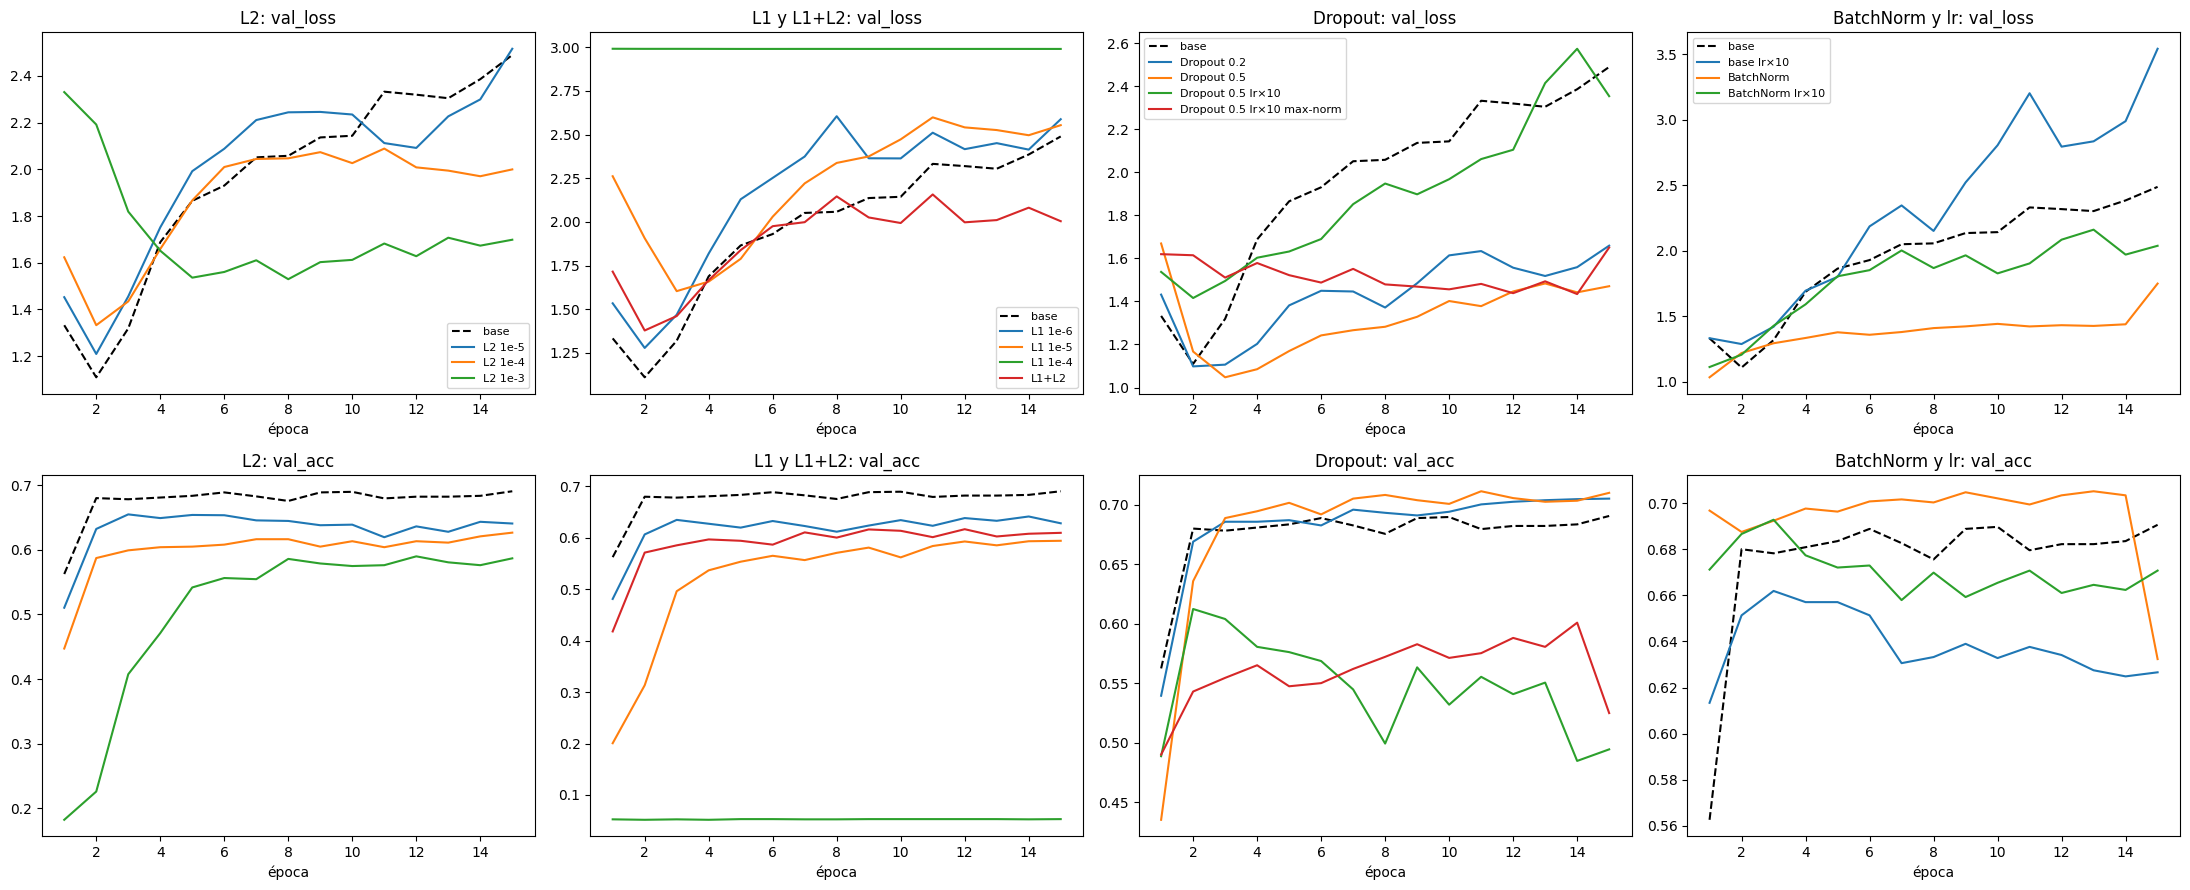

In [15]:
grupos = {
    "L2": ["base", "L2 1e-5", "L2 1e-4", "L2 1e-3"],
    "L1 y L1+L2": ["base", "L1 1e-6", "L1 1e-5", "L1 1e-4", "L1+L2"],
    "Dropout": ["base", "Dropout 0.2", "Dropout 0.5", "Dropout 0.5 lr×10", "Dropout 0.5 lr×10 max-norm"],
    "BatchNorm y lr": ["base", "base lr×10", "BatchNorm", "BatchNorm lr×10"],
}
fig, axes = plt.subplots(2, 4, figsize=(22, 9))
for j, (titulo, nombres) in enumerate(grupos.items()):
    for nm in nombres:
        h = exp_hist[nm]["hist"]
        ep = range(1, len(h["val_loss"]) + 1)
        estilo = "k--" if nm == "base" else "-"
        axes[0, j].plot(ep, h["val_loss"], estilo, label=nm)
        axes[1, j].plot(ep, h["val_acc"], estilo, label=nm)
    axes[0, j].set_title(f"{titulo}: val_loss")
    axes[1, j].set_title(f"{titulo}: val_acc")
    axes[0, j].legend(fontsize=8)
    for i in range(2):
        axes[i, j].set_xlabel("época")
plt.tight_layout()
plt.show()

### Train contra validación y ruido de las curvas

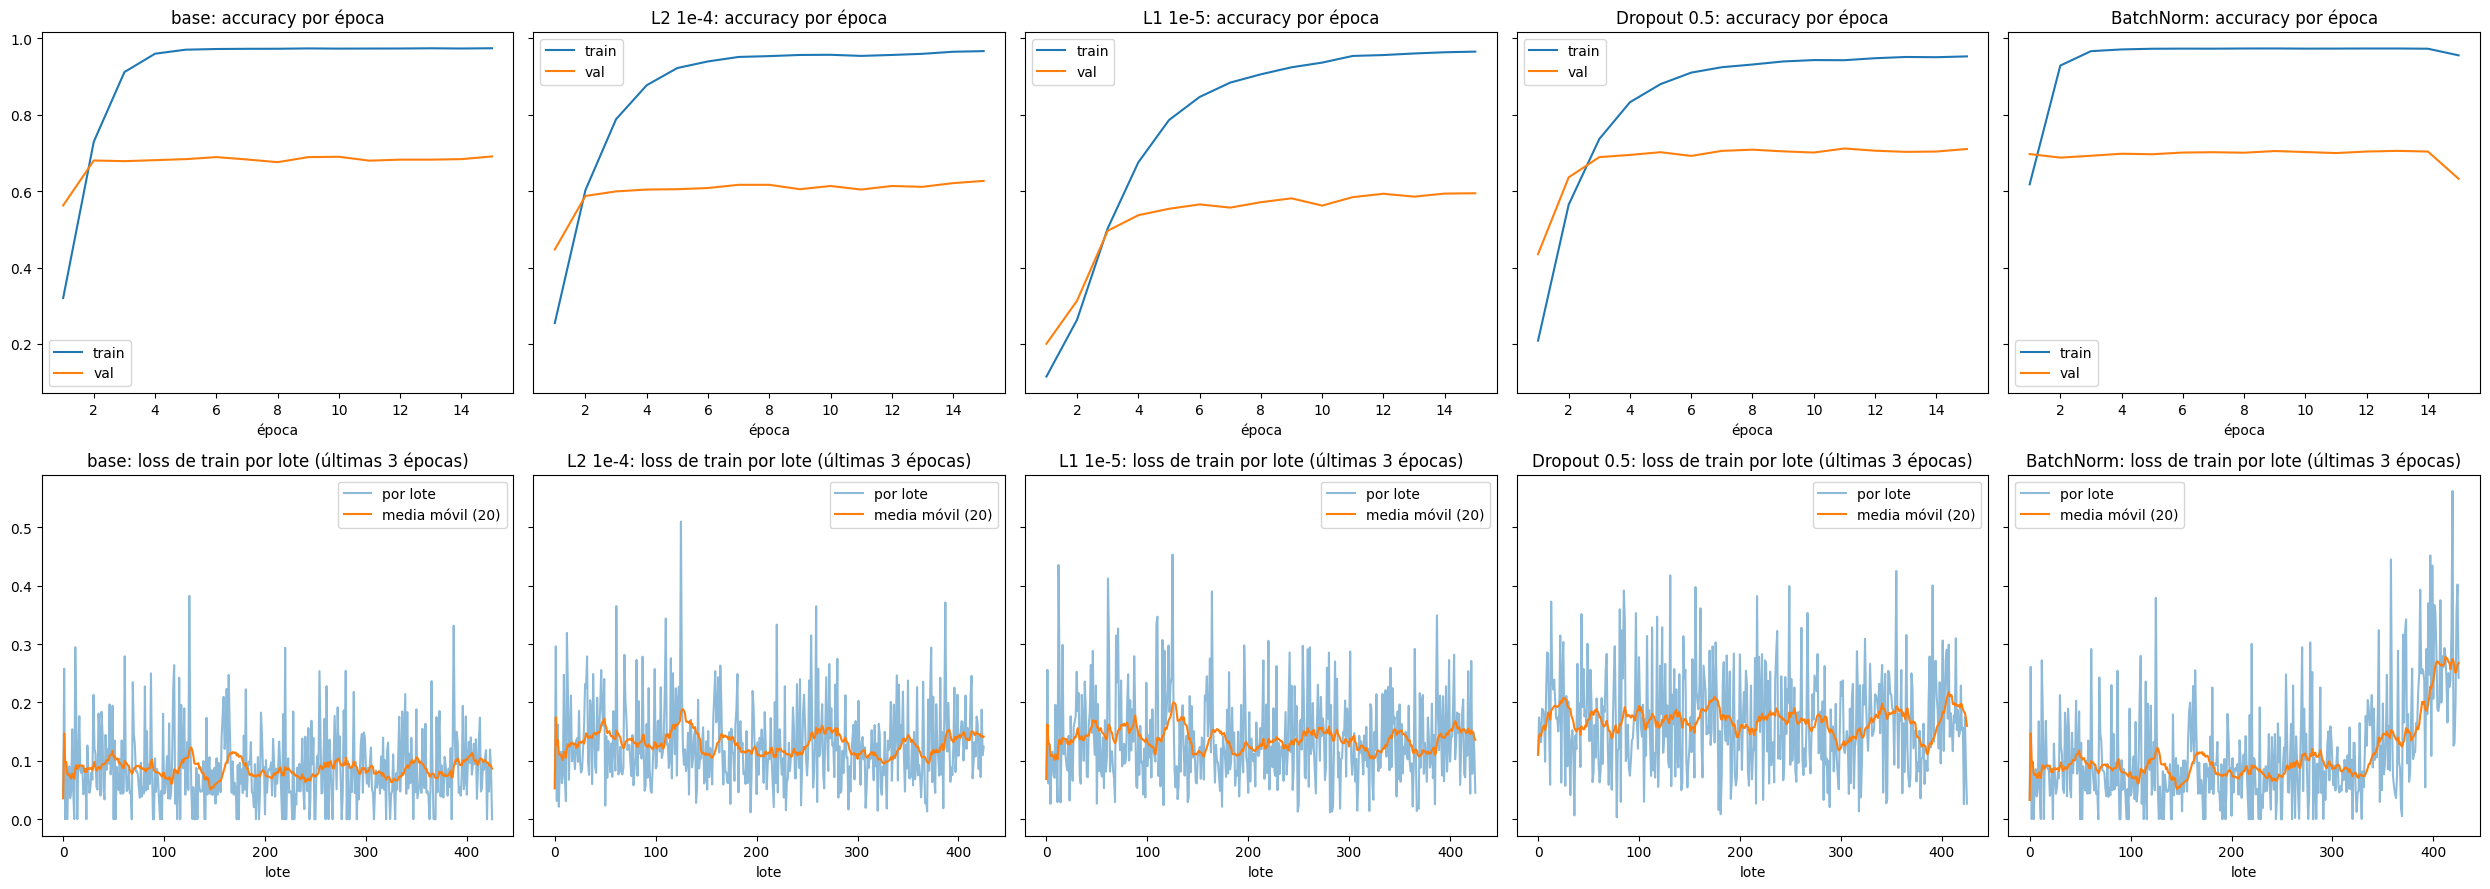

In [16]:
seleccion = ["base", "L2 1e-4", "L1 1e-5", "Dropout 0.5", "BatchNorm"]
fig, axes = plt.subplots(2, len(seleccion), figsize=(5 * len(seleccion), 9), sharey="row")
for j, nm in enumerate(seleccion):
    h = exp_hist[nm]["hist"]
    ep = range(1, len(h["val_acc"]) + 1)
    axes[0, j].plot(ep, h["train_acc"], label="train")
    axes[0, j].plot(ep, h["val_acc"], label="val")
    axes[0, j].set_title(f"{nm}: accuracy por época")
    axes[0, j].set_xlabel("época")
    axes[0, j].legend()
    b = np.array(h["batch_loss"])
    per_epoch = len(b) // len(h["val_acc"])
    ultimos = b[-3 * per_epoch:]
    axes[1, j].plot(ultimos, alpha=0.5, label="por lote")
    axes[1, j].plot(pd.Series(ultimos).rolling(20, min_periods=1).mean(), label="media móvil (20)")
    axes[1, j].set_title(f"{nm}: loss de train por lote (últimas 3 épocas)")
    axes[1, j].set_xlabel("lote")
    axes[1, j].legend()
plt.tight_layout()
plt.show()

### Valores absolutos de los pesos

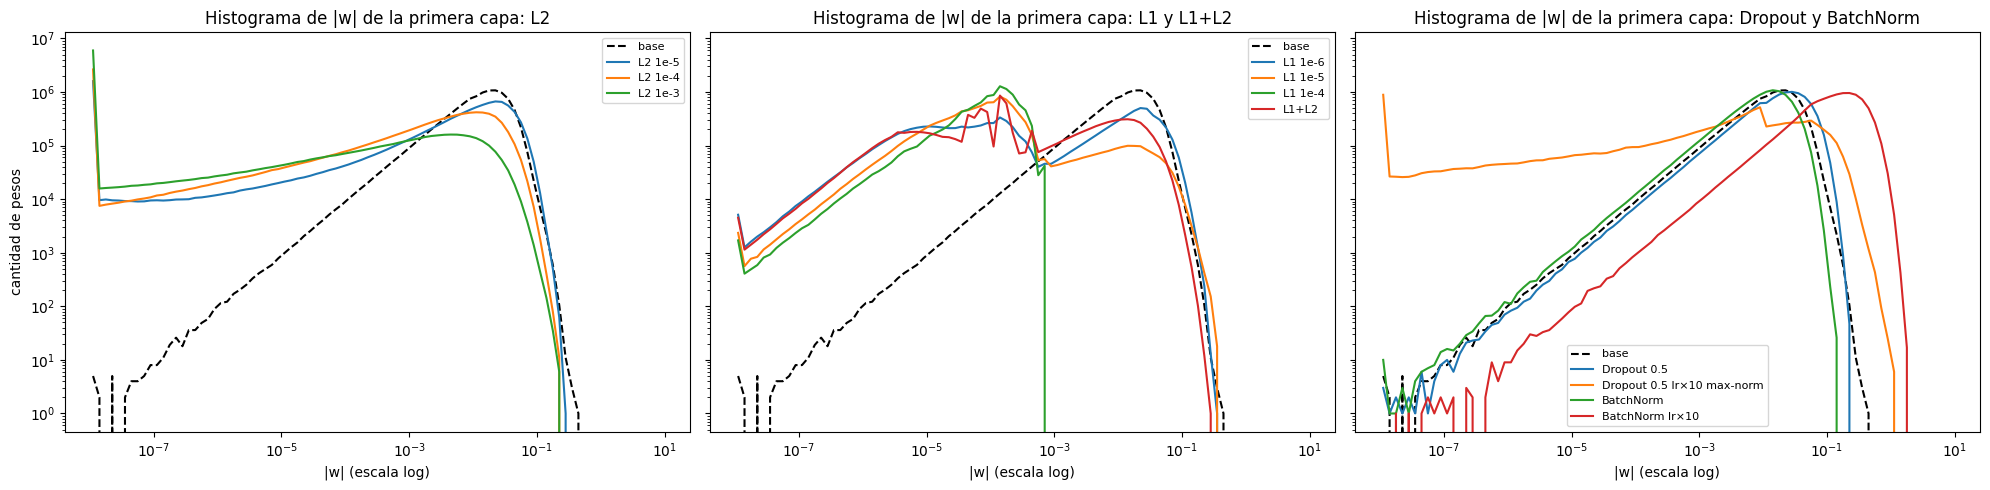

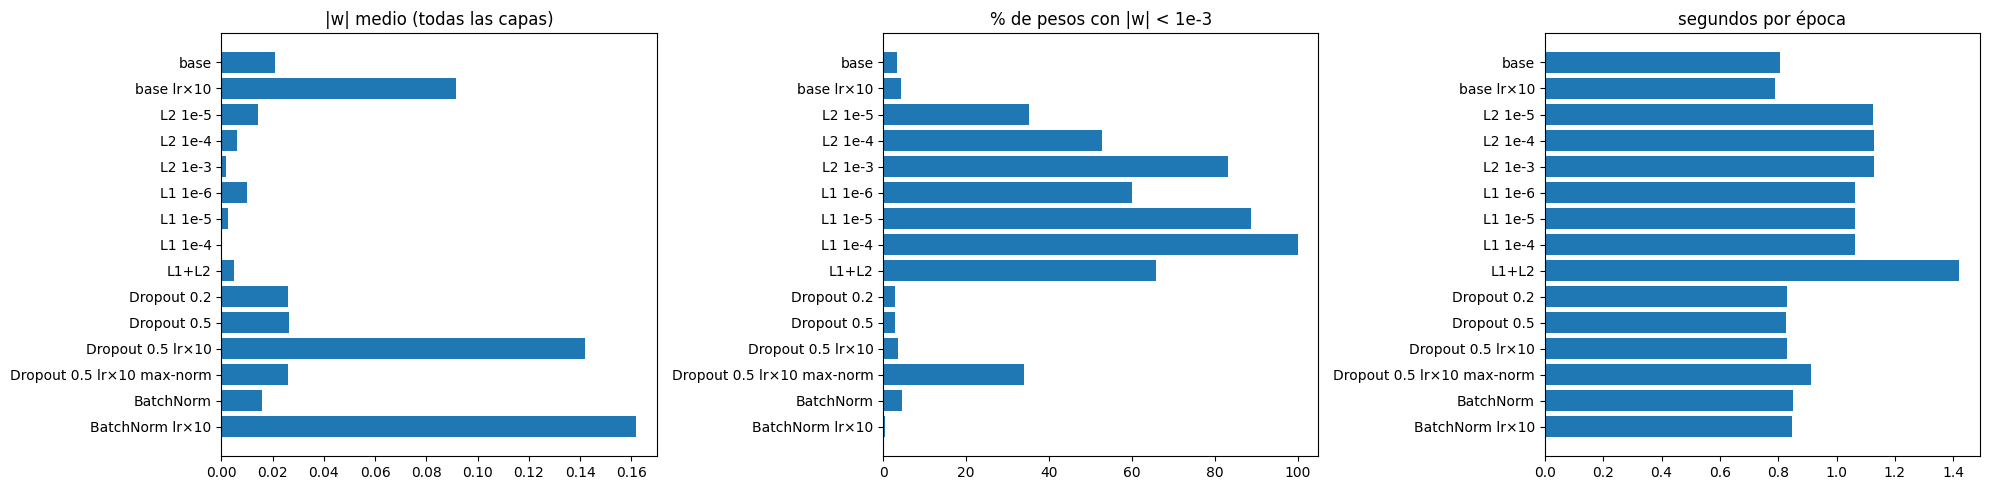

In [17]:
centros = 10 ** ((HIST_EDGES[:-1] + HIST_EDGES[1:]) / 2)
grupos_w = {
    "L2": ["base", "L2 1e-5", "L2 1e-4", "L2 1e-3"],
    "L1 y L1+L2": ["base", "L1 1e-6", "L1 1e-5", "L1 1e-4", "L1+L2"],
    "Dropout y BatchNorm": ["base", "Dropout 0.5", "Dropout 0.5 lr×10 max-norm", "BatchNorm", "BatchNorm lr×10"],
}
fig, axes = plt.subplots(1, 3, figsize=(20, 5), sharey=True)
for j, (titulo, nombres) in enumerate(grupos_w.items()):
    for nm in nombres:
        estilo = "k--" if nm == "base" else "-"
        axes[j].plot(centros, exp_hist[nm]["w_hist"], estilo, label=nm)
    axes[j].set_xscale("log")
    axes[j].set_yscale("log")
    axes[j].set_xlabel("|w| (escala log)")
    axes[j].set_title(f"Histograma de |w| de la primera capa: {titulo}")
    axes[j].legend(fontsize=8)
axes[0].set_ylabel("cantidad de pesos")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
r = resumen_exp.reset_index()
axes[0].barh(r["config"].astype(str), r["mean_abs_w"])
axes[0].set_title("|w| medio (todas las capas)")
axes[1].barh(r["config"].astype(str), r["pct_w_casi_cero"])
axes[1].set_title("% de pesos con |w| < 1e-3")
axes[2].barh(r["config"].astype(str), r["s_por_epoca"])
axes[2].set_title("segundos por época")
for ax in axes:
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

### Análisis de los experimentos

Promedios de 3 semillas, en validación. La base (sin regularizar) llega a 0.682 ± 0.009, con la `val_loss` subiendo de 1.15 a 2.31 y una diferencia de 0.30 entre train y validación.

| Configuración | val_acc | val_loss final | % pesos casi cero | s por época |
|---|---|---|---|---|
| Base | 0.682 | 2.31 | 3% | 0.81 |
| L2 1e-5 / 1e-4 / 1e-3 | 0.658 / 0.627 / 0.570 | 2.45 / 1.95 / 1.89 | 35% / 53% / 83% | 1.12 |
| L1 1e-6 / 1e-5 / 1e-4 | 0.644 / 0.574 / 0.053 | 2.58 / 2.85 / 2.99 | 60% / 89% / 100% | 1.06 |
| L1+L2 | 0.622 | 1.96 | 66% | 1.42 |
| Dropout 0.2 / 0.5 | 0.701 / 0.708 | 1.62 / 1.47 | 3% | 0.83 |
| Dropout 0.5 lr×10 / con max-norm | 0.606 / 0.608 | 2.33 / 1.50 | 4% / 34% | 0.83 / 0.91 |
| BatchNorm / lr×10 | 0.707 / 0.691 | 1.61 / 2.09 | 5% / 0.4% | 0.85 |

**L2.** Como se vio en clase, achica los pesos: el |w| medio baja de 0.021 a 0.002 y el histograma se corre hacia valores chicos. Con λ más grande la `val_loss` final es más baja (el modelo se vuelve menos "seguro"), pero la accuracy empeora en todos los casos. Acá L2 quita más capacidad de la que ayuda. Además, muchos pesos quedaron casi en cero, algo más típico de L1. Probablemente se debe a Adam: en las palabras que casi nunca aparecen, el único gradiente es el de la penalización, y Adam normaliza el tamaño del paso, así que esos pesos se van a cero.

**L1.** Genera pesos esparsos, como predice la teoría: con λ=1e-5 el 89% de los pesos queda casi en cero, lo que equivale a seleccionar palabras. Con λ=1e-4 la penalización anula todos los pesos: el modelo predice siempre la misma clase (0.053) y la `val_loss` queda en 2.99 ≈ ln(20). Es un caso claro de underfitting por λ demasiado grande. L1+L2 queda entre los dos.

**Dropout.** Fue la técnica que más ayudó: +2.6 puntos con 0.5 y la `val_loss` sube mucho menos que en la base. Como dice la teoría, necesita más épocas (la mejor llega en la época 13 o 14, contra 10 en la base) y la loss de train por lote es más alta y más ruidosa (≈0.17 contra ≈0.09), porque cada lote entrena una red distinta. La recomendación de clase de subir el `lr` ×10 es para SGD con momentum. Con Adam, `lr=1e-2` fue demasiado alto: la red empeora desde la época 3 y las normas de los pesos llegan a 36. Max-norm sí actuó (la norma máxima quedó exactamente en 4) y estabilizó el entrenamiento: la `val_loss` final bajó de 2.33 a 1.50. Pero el modelo queda tan limitado que la accuracy de train (0.49) queda por debajo de la de validación (0.61).

**BatchNorm.** Logra la menor `val_loss` de todos (1.03) y una accuracy similar a dropout (0.707), pero sigue sobreajustando (diferencia train/val de 0.29). Como se vio en clase, regulariza poco. Sí tolera mejor un `lr` alto: con `lr` ×10, BN llega a 0.691 contra 0.660 sin BN, y alcanza su mejor resultado en la época 2. Con `lr` alto los pesos crecen mucho (|w| medio 8 veces mayor). Probablemente es porque BN normaliza la salida de cada capa y entonces la escala de los pesos deja de importar. En la época 15 de una de las semillas, train y validación caen de golpe, una señal de inestabilidad.

**Learning rate.** Sin regularización, `lr` ×10 empeoró todo (0.660, `val_loss` final 3.32, normas de 31). El `lr` no cambia el tiempo por época, pero sí cuántas épocas hacen falta y qué tan estable es el entrenamiento.

**Tiempos.** L1 y L2 son las más caras: +30% a +75% por época, porque la penalización se calcula sobre 12 millones de pesos en cada lote. Dropout (+3%) y BatchNorm (+5%) casi no agregan costo, y max-norm agrega un 10%. Los 45 entrenamientos tardaron 683 s en total.

**Ruido.** Se ve mejor en los gráficos de loss por lote. La columna `ruido_rel` exagera el ruido cuando la loss está cerca de cero, así que no conviene usarla para comparar.

## 6. Búsqueda con Optuna incluyendo regularización

Mismo presupuesto y espacio que el TP2 (30 trials, 8 épocas, `MedianPruner`, preprocesamiento, `lr`, batch size, capas, neuronas, activación y optimizadores), más:

- `reg_type`: ninguna, L1, L2 o L1+L2, con `l1` entre 1e-7 y 1e-4 y `l2` entre 1e-6 y 1e-2 (escala logarítmica).
- `batchnorm`: sí o no.
- `dropout_in` (0, 0.1, 0.2) y `dropout_hidden` (0, 0.2, 0.3, 0.5), solo si no hay BatchNorm, siguiendo la recomendación de clase de no combinarlos.
- Se agregan 1024 neuronas como opción, porque en clase se recomienda una red grande cuando se regulariza.

El objetivo es la mejor `val_acc` entre las épocas de cada trial, igual que en el TP2.

In [18]:
def objective(trial):
    # --- Preprocesamiento ---
    remove_sw = trial.suggest_categorical("remove_stopwords", [False, True])
    norm = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    # --- Arquitectura ---
    n_layers = trial.suggest_int("n_layers", 1, 3)
    for i in range(n_layers):
        trial.suggest_categorical(f"n_units_l{i}", [64, 128, 256, 512, 1024])
    trial.suggest_categorical("activation", list(ACTIVATIONS))

    # --- Regularización ---
    reg_type = trial.suggest_categorical("reg_type", ["none", "l1", "l2", "l1_l2"])
    if reg_type in ("l1", "l1_l2"):
        trial.suggest_float("l1", 1e-7, 1e-4, log=True)
    if reg_type in ("l2", "l1_l2"):
        trial.suggest_float("l2", 1e-6, 1e-2, log=True)
    use_bn = trial.suggest_categorical("batchnorm", [False, True])
    if not use_bn:
        trial.suggest_categorical("dropout_in", [0.0, 0.1, 0.2])
        trial.suggest_categorical("dropout_hidden", [0.0, 0.2, 0.3, 0.5])

    # --- Optimizador y learning rate ---
    opt_name = trial.suggest_categorical("optimizer", ["adam", "rmsprop", "sgd"])
    if opt_name == "sgd":
        trial.suggest_float("lr_sgd", 1e-2, 10.0, log=True)
    else:
        trial.suggest_float("lr", 1e-4, 1e-1, log=True)
    if opt_name == "adam":
        trial.suggest_float("adam_beta1", 0.8, 0.99)
        trial.suggest_float("adam_beta2", 0.9, 0.9999)
    elif opt_name == "rmsprop":
        trial.suggest_float("rmsprop_alpha", 0.8, 0.999)
        trial.suggest_float("rmsprop_momentum", 0.0, 0.9)
    else:
        trial.suggest_float("sgd_momentum", 0.0, 0.95)

    cfg = config_from_params(trial.params)

    # --- Datos ---
    t0 = time.perf_counter()
    X_tr_sp, X_val_sp = get_search_features(remove_sw, norm, cfg["ngram"], max_features, min_df)
    X_tr, y_tr_t = to_device(X_tr_sp, y_tr)
    X_val, y_val_t = to_device(X_val_sp, y_val)
    trial.set_user_attr("prep_time_s", time.perf_counter() - t0)

    # --- Modelo y entrenamiento ---
    torch.manual_seed(SEED + trial.number)
    model = MLP(X_tr.shape[1], cfg["hidden"], NUM_CLASSES, cfg["activation"],
                dropout_in=cfg["dropout_in"], dropout_hidden=cfg["dropout_hidden"], batchnorm=cfg["batchnorm"])
    optimizer = make_optimizer(opt_name, model.parameters(), cfg["lr"], opt_kwargs_from(trial.params))
    trial.set_user_attr("n_params", count_params(model))

    with mlflow.start_run(run_name=f"trial_{trial.number}"):
        mlflow.log_params(trial.params)
        t1 = time.perf_counter()
        try:
            hist = train_model(model, X_tr, y_tr_t, X_val, y_val_t, optimizer, EPOCHS_SEARCH, batch_size,
                               l1=cfg["l1"], l2=cfg["l2"], trial=trial,
                               run_name=f"trial_{trial.number}", verbose=False)
        finally:
            trial.set_user_attr("train_time_s", time.perf_counter() - t1)
            mlflow.log_metric("train_time_s", time.perf_counter() - t1)

    trial.set_user_attr("history", {k: v for k, v in hist.items() if k != "batch_loss"})
    trial.set_user_attr("best_epoch", int(np.argmax(hist["val_acc"])) + 1)
    trial.set_user_attr("mean_abs_w", weight_stats(model)["mean_abs_w"])
    return max(hist["val_acc"])

In [19]:
optuna.logging.set_verbosity(optuna.logging.INFO)
study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2),
)
t0 = time.perf_counter()
study.optimize(objective, n_trials=N_TRIALS, timeout=TIMEOUT_S)
search_time = time.perf_counter() - t0

states = pd.Series([t.state.name for t in study.trials]).value_counts()
print(f"\nBúsqueda: {search_time:.1f} s | trials por estado:\n{states.to_string()}")
print("\nMejor val_acc:", round(study.best_value, 4))
print("Mejor época:", study.best_trial.user_attrs["best_epoch"])
print("Mejores hiperparámetros:", study.best_params)

[I 2026-11-19 13:42:39,390] A new study created in memory with name: no-name-21eccb2f-e60a-430b-b861-f31119ea3336
[I 2026-11-19 13:42:45,483] Trial 0 finished with value: 0.38267786124613345 and parameters: {'remove_stopwords': True, 'normalization': 'none', 'ngram_range': '1gram', 'max_features': 2000, 'min_df': 2, 'batch_size': 32, 'n_layers': 1, 'n_units_l0': 512, 'activation': 'gelu', 'reg_type': 'l2', 'l2': 0.000269264691008618, 'batchnorm': False, 'dropout_in': 0.1, 'dropout_hidden': 0.3, 'optimizer': 'rmsprop', 'lr': 0.053451661106468214, 'rmsprop_alpha': 0.8514972163384034, 'rmsprop_momentum': 0.5962700559185838}. Best is trial 0 with value: 0.38267786124613345.
[I 2026-11-19 13:42:56,838] Trial 1 finished with value: 0.36897923110914715 and parameters: {'remove_stopwords': True, 'normalization': 'lemmatize', 'ngram_range': '1_2gram', 'max_features': 10000, 'min_df': 2, 'batch_size': 64, 'n_layers': 3, 'n_units_l0': 1024, 'n_units_l1': 128, 'n_units_l2': 64, 'activation': 'leak


Búsqueda: 157.8 s | trials por estado:
COMPLETE    18
PRUNED      12

Mejor val_acc: 0.7375
Mejor época: 2
Mejores hiperparámetros: {'remove_stopwords': False, 'normalization': 'stem', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 1, 'batch_size': 64, 'n_layers': 1, 'n_units_l0': 512, 'activation': 'leaky_relu', 'reg_type': 'none', 'batchnorm': False, 'dropout_in': 0.1, 'dropout_hidden': 0.5, 'optimizer': 'adam', 'lr': 0.003298888896050272, 'adam_beta1': 0.813401981290741, 'adam_beta2': 0.901369406072217}


In [20]:
rows = []
for t in study.trials:
    h = t.user_attrs.get("history", {})
    if t.state.name not in ("COMPLETE", "PRUNED") or not h.get("val_acc"):
        continue
    p = t.params
    cfg = config_from_params(p)
    reg = "BatchNorm" if cfg["batchnorm"] else ("Dropout" if cfg["dropout_in"] + cfg["dropout_hidden"] > 0 else "-")
    rows.append({
        "trial": t.number,
        "estado": t.state.name,
        "best_val_acc": max(h["val_acc"]),
        "best_epoch": int(np.argmax(h["val_acc"])) + 1,
        "train_acc_final": h["train_acc"][-1],
        "epocas": len(h["val_acc"]),
        "t_por_epoca_s": float(np.mean(h["epoch_time"])),
        "n_params": t.user_attrs.get("n_params"),
        "reg_type": p["reg_type"],
        "l1": cfg["l1"],
        "l2": cfg["l2"],
        "bn_dropout": reg,
        "dropout_in": cfg["dropout_in"],
        "dropout_hidden": cfg["dropout_hidden"],
        "optimizer": p["optimizer"],
        "lr": cfg["lr"],
        "activation": p["activation"],
        "n_layers": p["n_layers"],
        "neuronas": "-".join(str(n) for n in cfg["hidden"]),
        "batch_size": p["batch_size"],
        "max_features": p["max_features"],
    })
df_trials = pd.DataFrame(rows).sort_values("best_val_acc", ascending=False).reset_index(drop=True)
df_trials["gap_train_val"] = df_trials["train_acc_final"] - df_trials["best_val_acc"]
df_trials.round(5)

,trial,estado,best_val_acc,best_epoch,train_acc_final,epocas,t_por_epoca_s,n_params,reg_type,l1,...,dropout_in,dropout_hidden,optimizer,lr,activation,n_layers,neuronas,batch_size,max_features,gap_train_val
0,13,COMPLETE,0.73752,2,0.95393,8,0.42745,5130772,none,0.00000,...,0.1,0.5,adam,0.00330,leaky_relu,1,512,64,10000,0.21641
1,22,COMPLETE,0.73045,8,0.90299,8,0.52619,5666324,none,0.00000,...,0.1,0.5,adam,0.00062,leaky_relu,2,512-1024,64,10000,0.17255
2,27,COMPLETE,0.72382,2,0.97382,8,0.57420,5323796,none,0.00000,...,0.0,0.0,rmsprop,0.00022,leaky_relu,3,512-256-256,64,10000,0.25000
3,29,COMPLETE,0.71675,1,0.97382,8,0.47978,4959252,none,0.00000,...,0.0,0.0,adam,0.00028,leaky_relu,2,512-256,64,10000,0.25707
4,12,COMPLETE,0.70835,6,0.86952,8,0.24963,641364,none,0.00000,...,0.1,0.5,adam,0.00284,gelu,1,64,64,10000,0.16117
5,2,COMPLETE,0.70703,8,0.88421,8,0.42415,5130772,none,0.00000,...,0.1,0.5,adam,0.00080,gelu,1,512,64,10000,0.17719
6,16,COMPLETE,0.70526,1,0.96763,8,0.30304,641428,l2,0.00000,...,0.0,0.0,adam,0.00466,leaky_relu,1,64,64,10000,0.26237
7,11,COMPLETE,0.70128,7,0.90465,8,0.26529,641364,none,0.00000,...,0.1,0.5,adam,0.00414,gelu,1,64,64,10000,0.20337
8,28,COMPLETE,0.69819,2,0.97370,8,0.37014,1384724,none,0.00000,...,0.0,0.0,rmsprop,0.00022,leaky_relu,3,128-256-256,64,10000,0.27552
9,24,COMPLETE,0.69554,3,0.95901,8,0.26298,727124,none,0.00000,...,0.1,0.0,adam,0.01103,relu,2,64-1024,64,10000,0.26347


In [21]:
# Resumen por técnica de regularización (solo trials completos)
completos = df_trials[df_trials["estado"] == "COMPLETE"]
for col in ["reg_type", "bn_dropout", "dropout_hidden", "optimizer", "n_layers"]:
    resumen = completos.groupby(col).agg(n=("trial", "count"),
                                         val_acc_media=("best_val_acc", "mean"),
                                         val_acc_max=("best_val_acc", "max"),
                                         gap_medio=("gap_train_val", "mean"),
                                         t_por_epoca_media=("t_por_epoca_s", "mean"))
    print(f"\n=== {col} ===")
    print(resumen.round(4).to_string())

podados = df_trials[df_trials["estado"] == "PRUNED"]
ahorro = ((EPOCHS_SEARCH - podados["epocas"]) * podados["t_por_epoca_s"]).sum()
print(f"\nPodados: {len(podados)} de {len(df_trials)} | tiempo de entrenamiento ahorrado (estimado): {ahorro:.1f} s")


=== reg_type ===
           n  val_acc_media  val_acc_max  gap_medio  t_por_epoca_media
reg_type                                                              
l1         1         0.6624       0.6624     0.1783             0.7232
l1_l2      2         0.6337       0.6823     0.3227             0.3881
l2         3         0.5918       0.7053     0.1170             0.5164
none      12         0.6739       0.7375     0.1868             0.4631

=== bn_dropout ===
             n  val_acc_media  val_acc_max  gap_medio  t_por_epoca_media
bn_dropout                                                              
BatchNorm    6         0.6852       0.7238     0.2817             0.4172
Dropout     12         0.6401       0.7375     0.1439             0.5085

=== dropout_hidden ===
                n  val_acc_media  val_acc_max  gap_medio  t_por_epoca_media
dropout_hidden                                                             
0.0             8         0.6837       0.7238     0.2665            

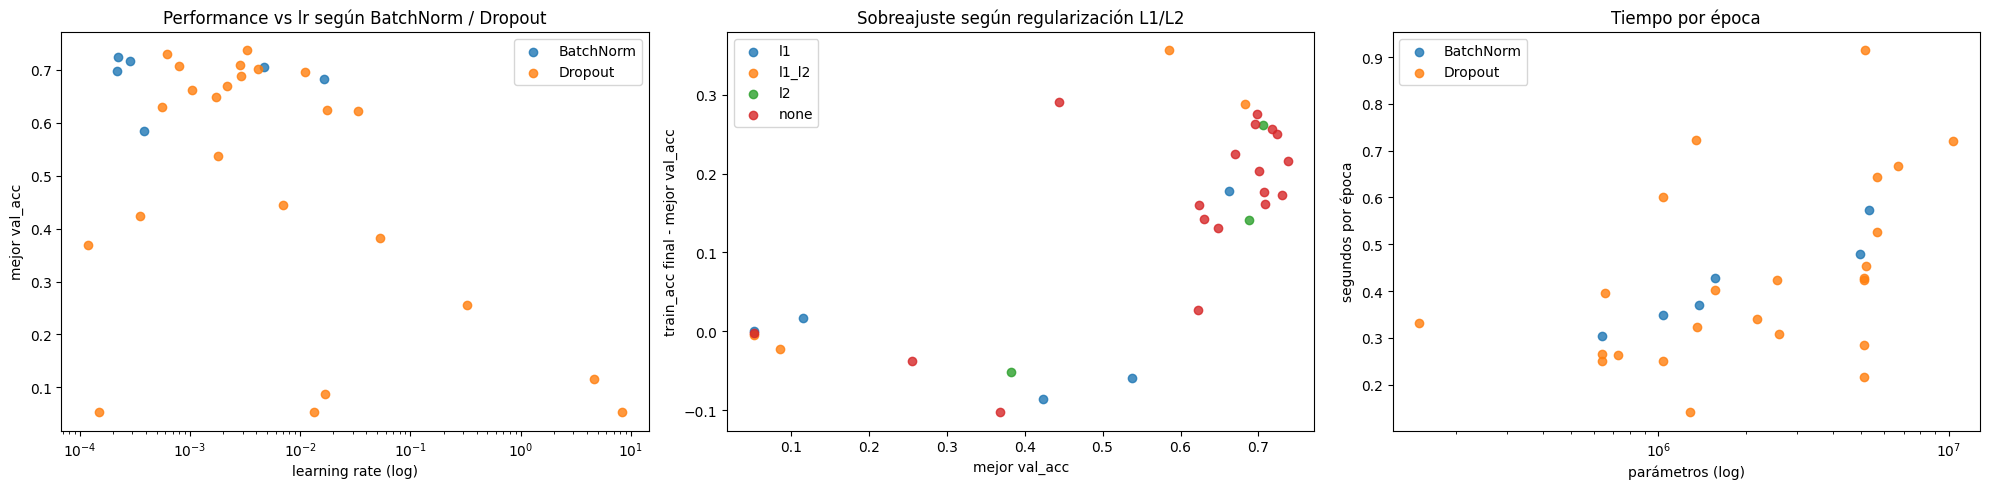

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for tipo, g in df_trials.groupby("bn_dropout"):
    axes[0].scatter(g["lr"], g["best_val_acc"], label=tipo, alpha=0.8)
axes[0].set_xscale("log")
axes[0].set_xlabel("learning rate (log)")
axes[0].set_ylabel("mejor val_acc")
axes[0].set_title("Performance vs lr según BatchNorm / Dropout")
axes[0].legend()

for tipo, g in df_trials.groupby("reg_type"):
    axes[1].scatter(g["best_val_acc"], g["gap_train_val"], label=tipo, alpha=0.8)
axes[1].set_xlabel("mejor val_acc")
axes[1].set_ylabel("train_acc final - mejor val_acc")
axes[1].set_title("Sobreajuste según regularización L1/L2")
axes[1].legend()

for tipo, g in df_trials.groupby("bn_dropout"):
    axes[2].scatter(g["n_params"], g["t_por_epoca_s"], label=tipo, alpha=0.8)
axes[2].set_xscale("log")
axes[2].set_xlabel("parámetros (log)")
axes[2].set_ylabel("segundos por época")
axes[2].set_title("Tiempo por época")
axes[2].legend()
plt.tight_layout()
plt.show()

### Análisis de la búsqueda

30 trials en 158 s: 18 completos y 12 podados (el pruning ahorró unos 21 s). El mejor (val_acc 0.7375, en la época 2) es una red de 1 capa de 512 neuronas con LeakyReLU, **dropout 0.1 en la entrada y 0.5 en la capa oculta**, sin L1/L2 ni BatchNorm, con Adam (`lr≈0.0033`) y batch 64.

- **Dropout:** los dos mejores trials usan dropout 0.5. Los trials con dropout 0.5 tienen menos diferencia entre train y validación (0.15) que los que no lo usan (0.27).
- **L1 / L2:** Optuna eligió "ninguna" en 12 de los 18 trials completos, y el mejor con L2 llegó a 0.705. Coincide con los experimentos controlados: en este problema L1 y L2 no mejoran la accuracy.
- **BatchNorm:** 6 trials completos, el mejor con 0.724. Funciona bien, pero sobreajusta más (diferencia media 0.28).
- **Optimizador:** Adam vuelve a ser el más estable (media 0.706). SGD tuvo un solo trial completo (0.682) y 4 podados, varios con `lr` demasiado alto (hasta 8.4).

Con 30 trials y muchos hiperparámetros cambiando a la vez, estas comparaciones son tendencias. Las conclusiones más firmes salen de los experimentos controlados.

## 7. Entrenamiento final y evaluación en test

Mejores hiperparámetros de la búsqueda, todo el train y la cantidad de épocas elegida en validación. En la salida de la celda de entrenamiento, `val_loss` y `val_acc` corresponden al **test**.

In [23]:
bp = study.best_params
cfg_best = config_from_params(bp)
BEST_EPOCHS = study.best_trial.user_attrs["best_epoch"]
train_texts, test_texts = preprocessed_cache[(bp["remove_stopwords"], bp["normalization"])]
X_train_sp, X_test_sp, _ = vectorize_data(train_texts, test_texts, cfg_best["ngram"],
                                          bp["max_features"], bp["min_df"])
X_train_t, y_train_t = to_device(X_train_sp, y_train_full)
X_test_t, y_test_t = to_device(X_test_sp, y_test)


def build_best(seed):
    torch.manual_seed(seed)
    m = MLP(X_train_t.shape[1], cfg_best["hidden"], NUM_CLASSES, cfg_best["activation"],
            dropout_in=cfg_best["dropout_in"], dropout_hidden=cfg_best["dropout_hidden"],
            batchnorm=cfg_best["batchnorm"]).to(device)
    o = make_optimizer(bp["optimizer"], m.parameters(), cfg_best["lr"], opt_kwargs_from(bp))
    return m, o


mlp_final, opt_final = build_best(SEED)
print(mlp_final)
print("Parámetros:", count_params(mlp_final), "| Épocas:", BEST_EPOCHS,
      "| L1:", cfg_best["l1"], "| L2:", cfg_best["l2"])

with mlflow.start_run(run_name="mlp_final"):
    mlflow.log_params({**bp, "epochs": BEST_EPOCHS})
    t0 = time.perf_counter()
    hist_final = train_model(mlp_final, X_train_t, y_train_t, X_test_t, y_test_t, opt_final, BEST_EPOCHS,
                             bp["batch_size"], l1=cfg_best["l1"], l2=cfg_best["l2"], run_name="mlp_final")
    final_time = time.perf_counter() - t0
print(f"Tiempo de entrenamiento final: {final_time:.1f} s")

MLP(
  (net): Sequential(
    (0): Dropout(p=0.1, inplace=False)
    (1): Linear(in_features=10000, out_features=512, bias=True)
    (2): LeakyReLU(negative_slope=0.01)
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=512, out_features=20, bias=True)
  )
)
Parámetros: 5130772 | Épocas: 2 | L1: 0.0 | L2: 0.0
[mlp_final] ep 1/2 - train_loss 1.7049 train_acc 0.5520 - val_loss 1.1351 val_acc 0.6657 - 0.53 s
[mlp_final] ep 2/2 - train_loss 0.7153 train_acc 0.7903 - val_loss 1.0577 val_acc 0.6925 - 0.54 s
Tiempo de entrenamiento final: 1.1 s


In [24]:
with torch.no_grad():
    mlp_final.eval()
    preds = torch.cat([mlp_final(X_test_t[i:i + EVAL_BATCH]).argmax(1)
                       for i in range(0, len(y_test), EVAL_BATCH)]).cpu().numpy()
test_acc = accuracy_score(y_test, preds)
print(f"Accuracy en test: {test_acc:.4f}\n")
print(classification_report(y_test, preds, target_names=class_names))

cm = confusion_matrix(y_test, preds)
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
print("Pares más confundidos:")
for i in np.argsort(cm_off, axis=None)[::-1][:10]:
    real, pred = divmod(i, NUM_CLASSES)
    print(f"{class_names[real]:>25} -> {class_names[pred]:<25} {cm_off[real, pred]}")

from collections import Counter
vacios = np.asarray(X_test_sp.sum(axis=1)).ravel() == 0
print("\nDocumentos de test sin ninguna feature:", vacios.sum())
print("Clase predicha para ellos:", Counter(class_names[p] for p in preds[vacios]))

Accuracy en test: 0.6925

                          precision    recall  f1-score   support

             alt.atheism       0.51      0.50      0.51       319
           comp.graphics       0.71      0.62      0.66       389
 comp.os.ms-windows.misc       0.62      0.60      0.61       394
comp.sys.ibm.pc.hardware       0.61      0.69      0.65       392
   comp.sys.mac.hardware       0.73      0.71      0.72       385
          comp.windows.x       0.74      0.72      0.73       395
            misc.forsale       0.80      0.78      0.79       390
               rec.autos       0.75      0.73      0.74       396
         rec.motorcycles       0.78      0.74      0.76       398
      rec.sport.baseball       0.57      0.85      0.69       397
        rec.sport.hockey       0.92      0.90      0.91       399
               sci.crypt       0.83      0.72      0.77       396
         sci.electronics       0.64      0.58      0.61       393
                 sci.med       0.81      0.76    

## 8. Variabilidad entre semillas y comparación con el TP2

La mejor configuración se repite con 5 semillas en validación (misma métrica que la búsqueda) y en test (igual que el entrenamiento final). Los valores del TP2 son los de su notebook (sección 10), obtenidos con el mismo procedimiento y las mismas semillas.

In [25]:
X_b_tr_sp, X_b_val_sp = get_search_features(bp["remove_stopwords"], bp["normalization"], cfg_best["ngram"],
                                            bp["max_features"], bp["min_df"])
X_b_tr, y_b_tr = to_device(X_b_tr_sp, y_tr)
X_b_val, y_b_val = to_device(X_b_val_sp, y_val)

val_accs, test_accs, t_epoca = [], [], []
for s in SEEDS_FINAL:
    m, o = build_best(s)
    h = train_model(m, X_b_tr, y_b_tr, X_b_val, y_b_val, o, EPOCHS_SEARCH, bp["batch_size"],
                    l1=cfg_best["l1"], l2=cfg_best["l2"], verbose=False)
    val_accs.append(max(h["val_acc"]))
    m, o = build_best(s)
    h = train_model(m, X_train_t, y_train_t, X_test_t, y_test_t, o, BEST_EPOCHS, bp["batch_size"],
                    l1=cfg_best["l1"], l2=cfg_best["l2"], verbose=False)
    test_accs.append(h["val_acc"][-1])
    t_epoca.append(np.mean(h["epoch_time"]))
val_accs, test_accs = np.array(val_accs), np.array(test_accs)

# Valores del TP2 (sección 10 de su notebook)
comparacion = pd.DataFrame({
    "TP2 Regresión softmax": {"val media": 0.7406, "val desvío": 0.0020, "test media": 0.6793, "test desvío": 0.0010},
    "TP2 MLP": {"val media": 0.7179, "val desvío": 0.0082, "test media": 0.6665, "test desvío": 0.0047},
    "TP3 MLP con regularización": {"val media": val_accs.mean(), "val desvío": val_accs.std(ddof=1),
                                   "test media": test_accs.mean(), "test desvío": test_accs.std(ddof=1)},
}).T
print(f"Mejor búsqueda TP3: val_acc {study.best_value:.4f} | TP2: MLP 0.7229, softmax 0.7415")
print(f"Tiempo por época del modelo final (test): {np.mean(t_epoca):.3f} s\n")
comparacion.round(4)

Mejor búsqueda TP3: val_acc 0.7375 | TP2: MLP 0.7229, softmax 0.7415
Tiempo por época del modelo final (test): 0.530 s



,val media,val desvío,test media,test desvío
TP2 Regresión softmax,0.7406,0.0020,0.6793,0.0010
TP2 MLP,0.7179,0.0082,0.6665,0.0047
TP3 MLP con regularización,0.7401,0.0035,0.6904,0.0032


### Análisis final y comparación con el TP2

El mejor modelo se entrenó 2 épocas (elegidas en validación) en 1.1 s. **Accuracy en test: 0.6925.** Las confusiones son las mismas familias de siempre (política, religión y computación), y los 230 documentos sin ninguna palabra del vocabulario van todos a `rec.sport.baseball`.

| 5 semillas | Validación | Test |
|---|---|---|
| TP2 Regresión softmax | 0.741 ± 0.002 | 0.679 ± 0.001 |
| TP2 MLP | 0.718 ± 0.008 | 0.667 ± 0.005 |
| **TP3 MLP con regularización** | **0.740 ± 0.004** | **0.690 ± 0.003** |

- Con el mismo presupuesto de búsqueda que el TP2, **el MLP regularizado mejora 2.2 puntos en validación y 2.4 en test** respecto del MLP sin regularizar.
- **Empata con la regresión softmax en validación y la supera en test por 1.1 puntos**, unas 2 veces el error de muestreo. Es la primera vez que un MLP no queda por debajo del modelo lineal.
- **Es más estable:** su desvío entre semillas es menos de la mitad que el del MLP del TP2. Dropout promedia muchas redes distintas, y eso reduce la dependencia de la inicialización.
- La mejora no viene solo de dropout, porque la búsqueda también cambió (por ejemplo, se agregaron 1024 neuronas como opción). Pero el experimento controlado muestra que dropout por sí solo aporta ≈2.6 puntos sobre la misma red.

**Conclusión.** En 20 Newsgroups con TF-IDF, el principal problema del MLP era sobreajustar en muy pocas épocas. Dropout fue la técnica que mejor lo resolvió, BatchNorm ayudó a aprender más rápido y a tolerar un `lr` más alto, y L1/L2 redujeron el tamaño de los pesos pero le quitaron demasiada capacidad al modelo.